# Exploring the hERG Dataset

In this notebook, we explore **what data we have, how the two classes of molecules differ, and how diverse their structures are**.

Run the cells in order with **Shift + Enter**, or select **Run All**. Explanations and chart labels are in English.

This is descriptive exploratory data analysis (EDA) of the full dataset. The observations do not establish causation and are not used to select a model threshold or hyperparameters. Future modeling decisions should rely only on the training partition.

## 1. Loading the data and understanding the columns

- `compound_id` — the compound identifier.
- `smiles` — a text representation of the molecular structure.
- `label` — the dataset label: **1 = inhibitor**, **0 = non-inhibitor**.
- `source_split` — the original partition provided by the source. Our pipeline creates its own scaffold split, so this column does not determine our model's test set.

Source: [Karim et al. dataset](https://huggingface.co/datasets/jablonkagroup/herg_karim_et_al), CC BY 4.0. See the project README for the full citation.

In [9]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from rdkit import Chem
from rdkit.Chem import Draw

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open this notebook from the project root or notebooks directory.")
sys.path.insert(0, str(ROOT))
from src.molecules import calculate_descriptors, scaffold_key

DATA_PATH = ROOT / "data/raw/herg_karim.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset missing: {DATA_PATH}. See README for the dataset source.")
df = pd.read_csv(DATA_PATH)
required = {"compound_id", "smiles", "label", "source_split"}
if not required.issubset(df.columns):
    raise ValueError(f"Missing columns: {required - set(df.columns)}")
if df.empty or df["label"].isna().any() or not set(df["label"]).issubset({0, 1}):
    raise ValueError("Expected nonempty data with binary labels 0 and 1.")
COLORS = {0: "#3677ad", 1: "#d57928"}
NAMES = {0: "Non-inhibitor (0)", 1: "Inhibitor (1)"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.18})
display(Markdown(f"**{len(df):,} compounds, {df.shape[1]} columns.**"))
display(df.head())

**13,445 compounds, 4 columns.**

,compound_id,smiles,label,source_split
0,1,COc1cc(N2Cc3ccc(Sc4ccc(F)cc4)nc3C2=O)ccc1OCCN1...,0,train
1,2,CCOC(=O)[C@H]1CC[C@@H](N2CC(NC(=O)CNc3nn(C(N)=...,0,train
2,5,Cc1cc(Nc2cncc(N[C@@H](C)c3ncc(F)cn3)n2)n[nH]1,0,train
3,7,CC(=O)SC1CC2=CC(=O)CCC2(C)C2CCC3(C)C(CCC34CCC(...,0,train
4,10,N[C@H]1C[C@@H](N2Cc3nn4cccnc4c3C2)CC[C@@H]1c1c...,0,train


## 2. Data quality

The same molecule can be written using different SMILES strings. We therefore also check **canonical SMILES**, a consistent representation generated by RDKit. This is not full standardization of salts, protonation states, or tautomers. Conflicting labels mean that the same canonical structure has both 0 and 1 labels.

In [10]:
display(df.isna().sum().rename("Missing values").to_frame())
molecules = [Chem.MolFromSmiles(s) if isinstance(s, str) else None for s in df["smiles"]]
invalid = [i for i, mol in enumerate(molecules) if mol is None or mol.GetNumAtoms() == 0]
if invalid:
    display(df.iloc[invalid])
    raise ValueError(f"Found {len(invalid)} invalid or empty molecular structures.")
df["canonical_smiles"] = [Chem.MolToSmiles(mol) for mol in molecules]
quality = pd.Series({
    "Repeated compound IDs": int(df.compound_id.duplicated().sum()),
    "Repeated raw SMILES": int(df.smiles.duplicated().sum()),
    "Repeated canonical structures": int(df.canonical_smiles.duplicated().sum()),
    "Structures with conflicting labels": int(df.groupby("canonical_smiles").label.nunique().gt(1).sum()),
    "Invalid molecular structures": len(invalid),
}, name="Count")
display(quality.to_frame())

,Missing values
compound_id,0
smiles,0
label,0
source_split,0


,Count
Repeated compound IDs,0
Repeated raw SMILES,0
Repeated canonical structures,0
Structures with conflicting labels,0
Invalid molecular structures,0


## 3. Class distribution

**How to read the chart:** bar height represents the number of compounds; the annotation gives the count and percentage. Similar bar heights indicate a balanced dataset. This does not mean that half of arbitrary compounds in the real world are inhibitors.

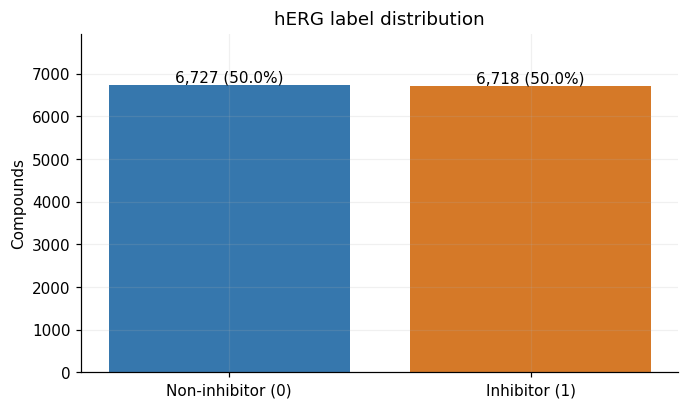

**Observation:** inhibitors account for **49.97%** of compounds. The classes in this dataset are nearly balanced.

In [11]:
counts = df.label.value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([NAMES[k] for k in counts.index], counts.values, color=[COLORS[k] for k in counts.index])
for i, count in enumerate(counts):
    ax.text(i, count, f"{count:,} ({count / len(df):.1%})", ha="center", va="bottom")
ax.set(ylabel="Compounds", title="hERG label distribution", ylim=(0, counts.max() * 1.18))
plt.show()
display(Markdown(f"**Observation:** inhibitors account for **{df.label.mean():.2%}** of compounds. The classes in this dataset are nearly balanced."))

## 4. Molecular properties

- **Molecular weight** — molecular mass in daltons (Da).
- **cLogP** — a calculated estimate of partitioning between lipid and aqueous environments; higher values generally indicate greater lipophilicity.
- **TPSA** — calculated topological polar surface area, in Å².
- **Hydrogen-bond donors / acceptors** — the number of hydrogen-bond donor / acceptor sites.
- **Rotatable bonds** — the number of rotatable bonds, a simple indicator of flexibility.

These are descriptive properties. The current model learns from **Morgan fingerprints**, rather than directly from these six columns.

In [12]:
descriptors = pd.DataFrame([calculate_descriptors(s) for s in df.smiles], index=df.index)
df = pd.concat([df, descriptors], axis=1)
properties = descriptors.columns.tolist()
display(descriptors.describe().round(2))
display(df.groupby("label")[properties].median().rename(index=NAMES).round(2))

,Molecular weight (Da),cLogP,TPSA (A^2),Hydrogen-bond donors,Hydrogen-bond acceptors,Rotatable bonds
count,13445.00,13445.00,13445.00,13445.00,13445.00,13445.00
mean,434.79,3.80,74.87,1.34,5.34,5.67
std,87.28,1.46,31.29,1.08,2.12,2.45
min,74.15,-4.61,0.00,0.00,0.00,0.00
25%,375.40,2.87,53.09,1.00,4.00,4.00
50%,436.51,3.78,74.38,1.00,5.00,6.00
75%,491.64,4.67,95.31,2.00,7.00,7.00
max,838.07,12.61,247.11,8.00,16.00,22.00


,Molecular weight (Da),cLogP,TPSA (A^2),Hydrogen-bond donors,Hydrogen-bond acceptors,Rotatable bonds
label,,,,,,
Non-inhibitor (0),436.45,3.3,84.34,1.0,6.0,5.0
Inhibitor (1),436.92,4.2,64.34,1.0,5.0,6.0


### Comparing the two class distributions

**How to read the charts:** the horizontal axis shows the property value, and the vertical axis shows probability density. Each class distribution is normalized separately so we can compare their shapes. Substantial overlap between the colors means that the property alone does not clearly separate the classes.

To keep the main patterns visible, we show the **1st–99th percentile range** for each property. Values outside that range remain in the dataset and are included in the summary table above.

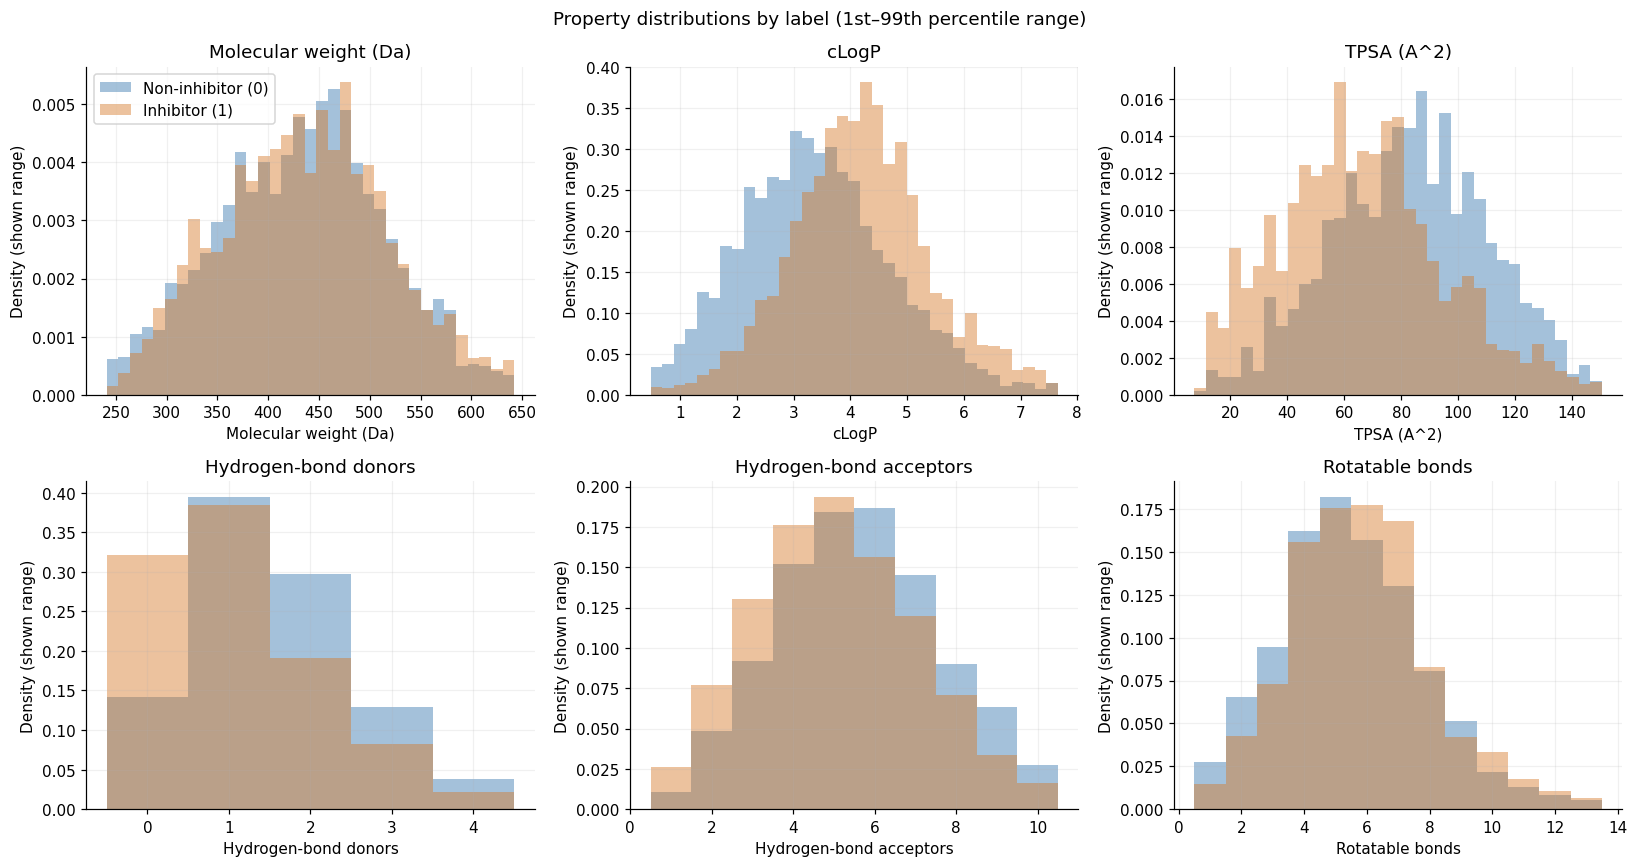

**Observation:** a difference in means or medians is not a ready-made classification rule. Also consider the overlap between the colored distributions.

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, prop in zip(axes.flat, properties):
    low, high = df[prop].quantile([0.01, 0.99])
    if prop in ["Hydrogen-bond donors", "Hydrogen-bond acceptors", "Rotatable bonds"]:
        bins = np.arange(np.floor(low) - 0.5, np.ceil(high) + 1.5)
    else:
        bins = np.linspace(low, high, 36)
    for label in [0, 1]:
        ax.hist(df.loc[df.label == label, prop], bins=bins, density=True,
                alpha=0.45, color=COLORS[label], label=NAMES[label])
    ax.set(title=prop, xlabel=prop, ylabel="Density (shown range)")
axes.flat[0].legend()
fig.suptitle("Property distributions by label (1st–99th percentile range)")
fig.tight_layout()
plt.show()
display(Markdown("**Observation:** a difference in means or medians is not a ready-made classification rule. Also consider the overlap between the colored distributions."))

### What we observed in this dataset

- **Molecular weight barely separates the classes:** the medians are approximately 436–437 Da. The median divides the observations into two halves.
- **Inhibitors have higher cLogP:** the median is 4.2, compared with 3.3 for non-inhibitors. The orange distribution is shifted to the right.
- **Inhibitors have lower TPSA:** the median is approximately 64 Å², compared with 84 Å² for non-inhibitors.
- **The distributions overlap substantially.** These are group-level trends; cLogP or TPSA alone cannot determine a compound's label.

These numbers refer to the data used in the saved notebook run. If the dataset changes, compare the updated results with the median table above.

## 5. Relationships between properties

In the left chart, each point is one compound, and its color represents the label. We select up to **3,000 random rows with a fixed seed** to reduce overplotting. The chart includes the full range of the sampled rows.

The right chart shows **Spearman correlations**, calculated using all rows. Values near +1 indicate that the properties tend to increase together; values near −1 indicate opposite directions; values near 0 indicate a weak monotonic relationship. Correlation does not establish causation.

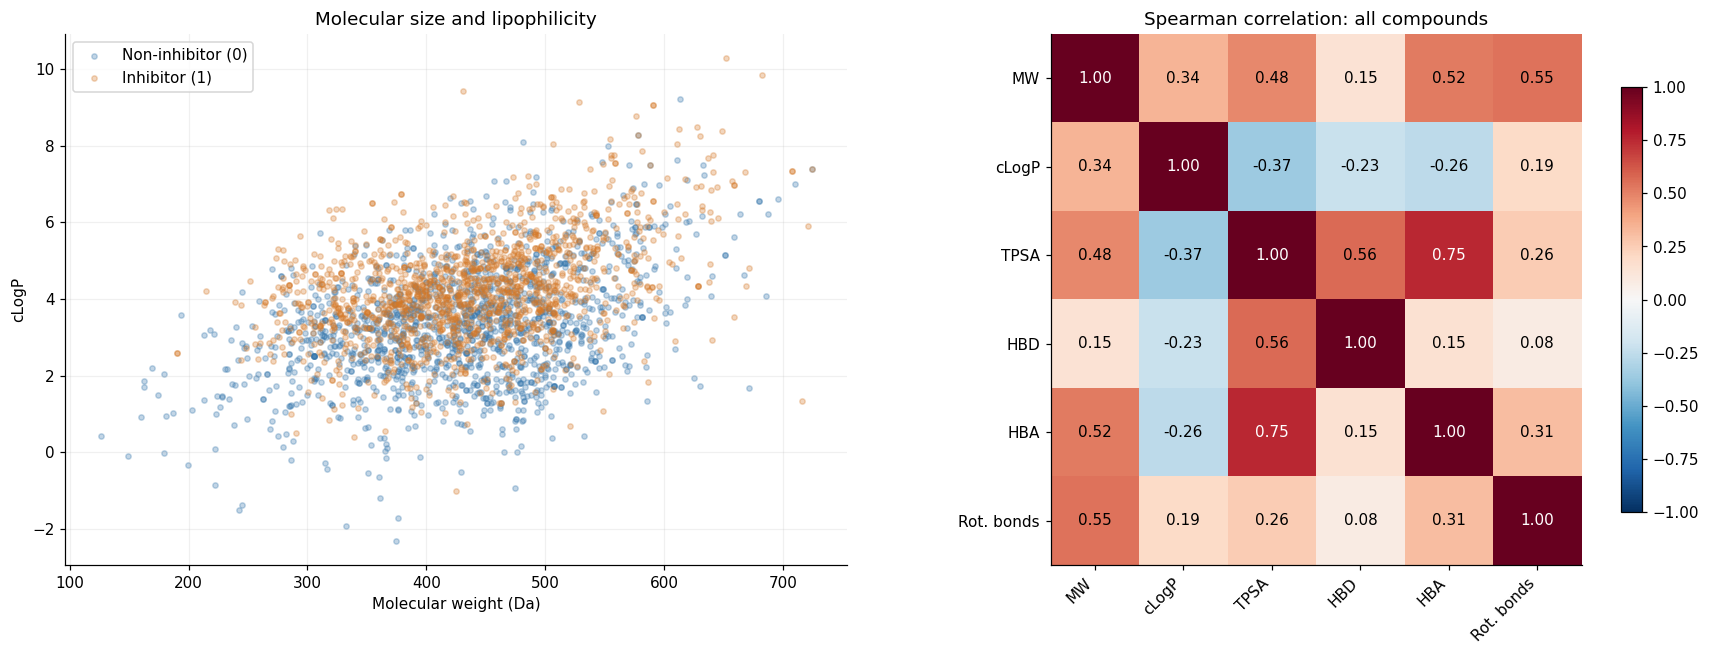

In [14]:
sample = df.sample(n=min(3000, len(df)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for label in [0, 1]:
    part = sample[sample.label == label]
    axes[0].scatter(part["Molecular weight (Da)"], part["cLogP"],
                    s=12, alpha=0.3, color=COLORS[label], label=NAMES[label])
axes[0].set(xlabel="Molecular weight (Da)", ylabel="cLogP", title="Molecular size and lipophilicity")
axes[0].legend()
short = ["MW", "cLogP", "TPSA", "HBD", "HBA", "Rot. bonds"]
corr = descriptors.corr(method="spearman")
im = axes[1].imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
axes[1].grid(False)
axes[1].set_xticks(range(6), short, rotation=45, ha="right")
axes[1].set_yticks(range(6), short)
axes[1].set_title("Spearman correlation: all compounds")
for i in range(6):
    for j in range(6):
        value = corr.iloc[i, j]
        axes[1].text(j, i, f"{value:.2f}", ha="center", va="center",
                     color="white" if abs(value) > 0.6 else "black")
fig.colorbar(im, ax=axes[1], shrink=0.8)
fig.tight_layout()
plt.show()

**Observation:** the colors overlap in the molecular weight–cLogP scatter plot; these two properties do not provide an obvious boundary between classes. In the correlation matrix, TPSA–HBA is approximately **0.75**: molecules with more hydrogen-bond acceptors often have a larger polar surface area. The cLogP–TPSA correlation is approximately **−0.37**, suggesting an inverse trend rather than a strict rule.

## 6. Structural diversity: scaffolds

A **Murcko scaffold** contains a molecule's rings and the structures linking them, with side chains removed. Molecules sharing the same scaffold can have different labels.

We use the project's `scaffold_key` function. For molecules without rings, it returns a separate key based on the complete canonical structure. A “group” below therefore does not always represent a ring scaffold. The training pipeline uses the same key to keep each scaffold on one side of a split. This does not guarantee that molecules with different scaffold keys are chemically dissimilar.

**6,806 structural groups**, of which **4,767** contain a single compound. Compounds without rings: **17**.

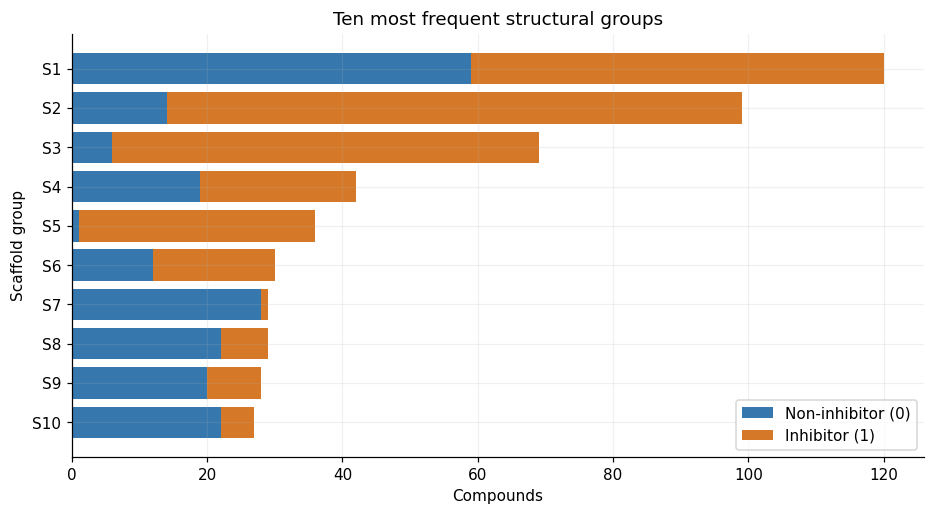

,group,scaffold,compounds,inhibitor_fraction
0,S1,c1ccccc1,120,0.508333
1,S2,O=C1COc2ccc(CNC34CCC(CCc5ccnc6cccnc56)(CC3)OC4...,99,0.858586
2,S3,c1ccc(Oc2ccccc2)cc1,69,0.913043
3,S4,O=C(CNc1n[nH]c2ccccc12)NC1CN(C2CCCCC2)C1,42,0.547619
4,S5,c1ccc(CCNCCOc2ccccc2)cc1,36,0.972222
5,S6,C1=C(c2ccccc2)c2ccccc2OC12CCNCC2,30,0.600000
6,S7,O=C1COc2ccc(CNC34CCC(CC5Cn6c(=O)ccc7nccc5c76)(...,29,0.034483
7,S8,c1ccc(CCN2CCC(CN3CCC(Oc4ccccc4)CC3)CC2)cc1,29,0.241379
8,S9,C1=C(CN2CCOCC2)NC(c2nccs2)=NC1c1ccccc1,28,0.285714
9,S10,c1ccc(-c2ccc3c(N4CCOCC4)nc(N4CCOCC4)nc3n2)cc1,27,0.185185


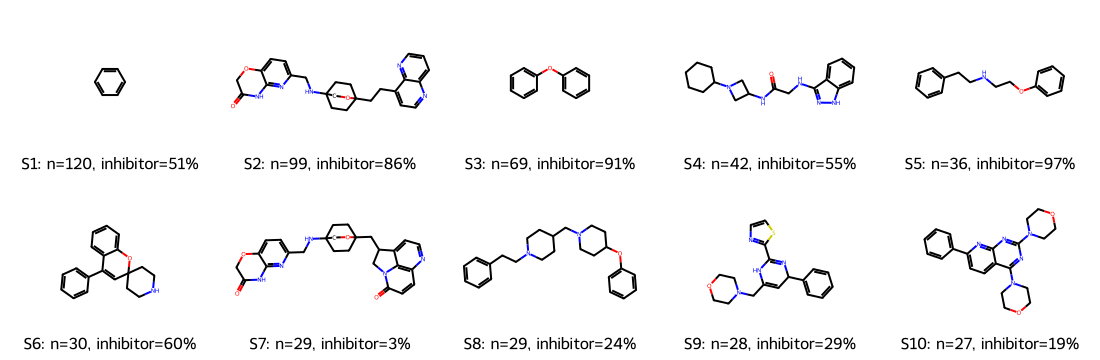

In [15]:
df["scaffold"] = df.smiles.map(scaffold_key)
scaffold_summary = df.groupby("scaffold").agg(
    compounds=("label", "size"), inhibitors=("label", "sum"))
scaffold_summary["inhibitor_fraction"] = scaffold_summary.inhibitors / scaffold_summary.compounds
scaffold_summary = scaffold_summary.sort_values("compounds", ascending=False)
display(Markdown(
    f"**{len(scaffold_summary):,} structural groups**, "
    f"of which **{scaffold_summary.compounds.eq(1).sum():,}** contain a single compound. "
    f"Compounds without rings: **{df.scaffold.str.startswith('acyclic:').sum()}**."))
top = scaffold_summary.head(10).copy()
top["group"] = [f"S{i}" for i in range(1, len(top) + 1)]
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top["group"], top.compounds - top.inhibitors, color=COLORS[0], label=NAMES[0])
ax.barh(top["group"], top.inhibitors, left=top.compounds - top.inhibitors,
        color=COLORS[1], label=NAMES[1])
ax.invert_yaxis()
ax.set(xlabel="Compounds", ylabel="Scaffold group", title="Ten most frequent structural groups")
ax.legend()
plt.show()
display(top.reset_index()[["group", "scaffold", "compounds", "inhibitor_fraction"]])
images = [Chem.MolFromSmiles(s.removeprefix("acyclic:")) for s in top.index]
display(Draw.MolsToGridImage(images, molsPerRow=5, subImgSize=(220, 180),
    legends=[f"{row['group']}: n={row.compounds}, inhibitor={row.inhibitor_fraction:.0%}"
             for _, row in top.iterrows()]))

**What we learn:** bar length shows how many examples represent a structure, while the colors show its class composition. Conclusions about structures with only one or a few examples are limited. Scaffold frequency and the fraction of inhibitor labels are not prediction probabilities for a compound.

## 7. Original source partitions

We also check the sizes and class composition of the original train/val/test partitions. These are **not our model's scaffold partitions**.

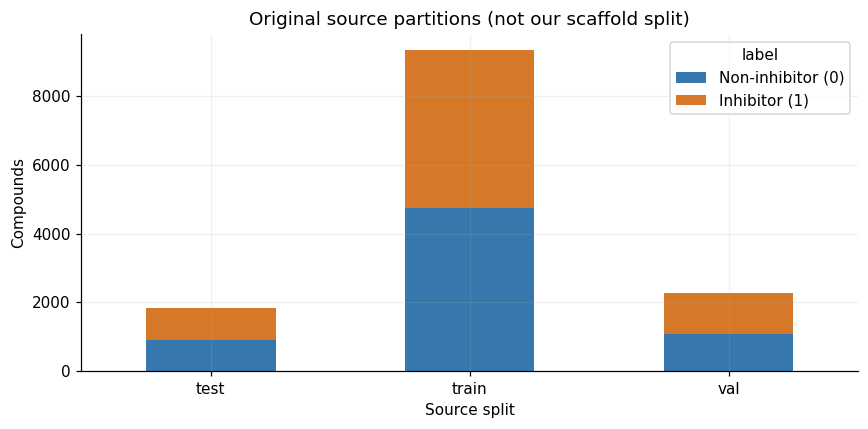

,compounds,inhibitor_fraction
source_split,,
test,1832,0.507096
train,9341,0.491061
val,2272,0.529049


**0 scaffold groups** appear in more than one original source partition. This does not imply leakage in our own scaffold split.

In [16]:
source_counts = pd.crosstab(df.source_split, df.label).reindex(columns=[0, 1], fill_value=0)
source_counts.rename(columns=NAMES).plot.bar(stacked=True, color=[COLORS[0], COLORS[1]], figsize=(8, 4))
plt.title("Original source partitions (not our scaffold split)")
plt.ylabel("Compounds")
plt.xlabel("Source split")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
source_summary = df.groupby("source_split").agg(compounds=("label", "size"), inhibitor_fraction=("label", "mean"))
display(source_summary)
# Count scaffold groups appearing in more than one original source partition.
shared = df.groupby("scaffold").source_split.nunique().gt(1).sum()
display(Markdown(f"**{shared:,} scaffold groups** appear in more than one original source partition. This does not imply leakage in our own scaffold split."))

## 8. Conclusions and the next step

- The calculations above describe data quality and class composition. The recorded labels do not provide the full context of the experimental measurements.
- Property distributions help identify differences and extreme values, but do not provide standalone prediction rules.
- Scaffold grouping reveals uneven representation of molecular structures and supports evaluating models using grouped partitions.
- **Next: a separate notebook analyzing model errors**, including the test-set confusion matrix, precision–recall curve, and examples of false positives and false negatives. This requires saving test predictions at evaluation time during training. Predictions from the demo model refitted on the full dataset cannot correctly reconstruct its earlier test performance.

After this full-dataset EDA, model changes guided by the test set would require a new independent evaluation.